# Sparse-scaling benchmark: physical properties

A cell doubled `d` times is still bulk Si, so every property per primitive cell must look the same
at every size. Each figure shows one sparse pipeline. The colored lines are its sizes, and the
dashed black line is the dense reference on the primitive cell (`reference_d00`).

The curves come from [observables.py](observables.py), which normalizes them per primitive cell.
Tensor quantities show the `xx` component. PDOS is left out. A pipeline that does not run a
property has no panel for it: the interior-window pipelines skip doping and the dielectric
tensor, and only `sparse_curvature` gives the Hall coefficient and the effective masses.

The notebook reads the output files directly, so it also works while the ladder is still running.

In [1]:
import glob
import os
import sys

import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import observables
from config import CONFIG

ROOT = os.environ.get('BENCH_OUTPUT_ROOT', CONFIG['output_root'])
PIPELINES = [name for name, p in CONFIG['pipelines'].items() if p['enabled'] and p['sparse']]
REFERENCE = 'reference_d00'

# palette: deep blue, vermillion, amber, then Okabe-Ito
PALETTE = ['#004488', '#D55E00', '#FFC20A', '#009E73', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})


def load_case(path):
    if not os.path.exists(os.path.join(path, 'record.json')):
        return None
    rec = observables.load_record(path)
    if rec.get('status') != 'ok':
        print('skipping %s: status %s' % (os.path.basename(path), rec.get('status')))
        return None
    return {
        'd': rec['case']['d'],
        'nawf': rec['hamiltonian']['nawf'],
        'curves': observables.load(path, pdos=False, optics=True),
    }


ref_case = load_case(os.path.join(ROOT, REFERENCE))
ref = ref_case['curves'] if ref_case else {}
if not ref:
    print('no finished %s yet: the figures show the sparse sizes only' % REFERENCE)

runs = {}
for pipeline in PIPELINES:
    paths = sorted(glob.glob(os.path.join(ROOT, pipeline + '_d[0-9][0-9]')))
    cases = [c for c in map(load_case, paths) if c is not None]
    if cases:
        runs[pipeline] = cases
        print('%-20s d = %s' % (pipeline, ', '.join(str(c['d']) for c in cases)))

no finished reference_d00 yet: the figures show the sparse sizes only
skipping sparse_d09: status running
sparse               d = 0, 1, 2, 3, 4, 5, 6, 7, 8


In [2]:
# name: (title, x label, y label)
LABELS = {
    'dos': ('DoS per primitive cell', 'E - E$_F$ (eV)', 'states/eV'),
    'doping_mu': ('μ at p = 10$^{18}$ cm$^{-3}$', 'T (K)', 'μ (eV)'),
    'sigma_xx': ('σ$_{xx}$/τ', 'μ (eV)', '1/(Ω m s)'),
    'seebeck_xx': ('Seebeck S$_{xx}$', 'μ (eV)', 'V/K'),
    'kappa_xx': ('κ$^{el}_{xx}$/τ', 'μ (eV)', 'W/(m K s)'),
    'pf_xx': ('power factor/τ, xx', 'μ (eV)', 'W/(m K$^2$ s)'),
    'hall_trace': ('Hall tensor trace', 'μ (eV)', ''),
    'cond_xx': ('σ$_{xx}$(E), band-diagonal', 'E - E$_F$ (eV)', ''),
    'cond_xy': ('σ$_{xy}$(E), band-diagonal', 'E - E$_F$ (eV)', ''),
    'epsi_xx': ('ε″$_{xx}$', 'ħω (eV)', ''),
    'epsr_xx': ('ε′$_{xx}$', 'ħω (eV)', ''),
    'eels_xx': ('EELS, -Im 1/ε$_{xx}$', 'ħω (eV)', ''),
    'refl_xx': ('reflectivity R$_{xx}$', 'ħω (eV)', ''),
    'nref_xx': ('refractive index n$_{xx}$', 'ħω (eV)', ''),
    'kref_xx': ('extinction κ$_{xx}$', 'ħω (eV)', ''),
    'alpha_xx': ('absorption α$_{xx}$', 'ħω (eV)', '1/m'),
    'sigmar_xx': ('Re σ$_{xx}$(ω)', 'ħω (eV)', ''),
    'sigmai_xx': ('Im σ$_{xx}$(ω)', 'ħω (eV)', ''),
    'inv_mass_dos': ('Σ g(E - E$_{nk}$) / m$^{dos}_{nk}$', 'E - E$_F$ (eV)', '1/(m$_e$ eV)'),
}


def style(d):
    return dict(color=PALETTE[d % len(PALETTE)], ls=('-', '--', ':')[d // len(PALETTE)], lw=1.1)


def describe(pipeline):
    sc = CONFIG['pipelines'][pipeline].get('sparse_config', {})
    parts = ['bond_order %d' % sc['bond_order']] if 'bond_order' in sc else []
    if 'energy_window' in sc:
        parts.append('states below %.1f eV' % sc['energy_window']['emax'])
    if 'interior_window' in sc:
        w = sc['interior_window']
        parts.append('interior window [%.1f, %.1f] eV' % (w['elo'], w['ehi']))
    return '%s: %s' % (pipeline, ', '.join(parts))


def show(names, ncol=3):
    # one figure per pipeline, one panel per property it ran
    for pipeline, cases in runs.items():
        present = [n for n in names if any(n in c['curves'] for c in cases)]
        if not present:
            continue
        nc = min(ncol, len(present))
        nr = -(-len(present) // nc)
        fig, axes = plt.subplots(nr, nc, figsize=(4.4 * nc, 3.2 * nr), squeeze=False)
        legend = {}
        for ax, name in zip(axes.flat, present):
            curves = [(c, c['curves'][name]) for c in cases if name in c['curves']]
            for c, cv in curves:
                ax.plot(
                    cv['x'], cv['y'], label='d=%d (nawf %d)' % (c['d'], c['nawf']), **style(c['d'])
                )
            if name in ref:
                ax.plot(ref[name]['x'], ref[name]['y'], 'k--', lw=1.0, label='dense reference')
            ax.set_xlim(
                min(cv['x'].min() for _, cv in curves), max(cv['x'].max() for _, cv in curves)
            )
            cuts = [cv['xmax'] for _, cv in curves if cv['xmax'] is not None]
            if cuts:
                ax.axvline(min(cuts), color='#888888', lw=0.8)
            title, xlabel, ylabel = LABELS[name]
            ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
            legend.update(zip(*reversed(ax.get_legend_handles_labels())))
        for ax in axes.flat[len(present) :]:
            ax.axis('off')
        fig.suptitle(describe(pipeline))
        fig.tight_layout()
        fig.legend(
            legend.values(), legend.keys(), loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8
        )
        plt.show()

## 1. Density of states and doping

The DoS per primitive cell, and the chemical potential against temperature at a p-type doping of
10¹⁸ cm⁻³. The interior-window DoS covers the window only.

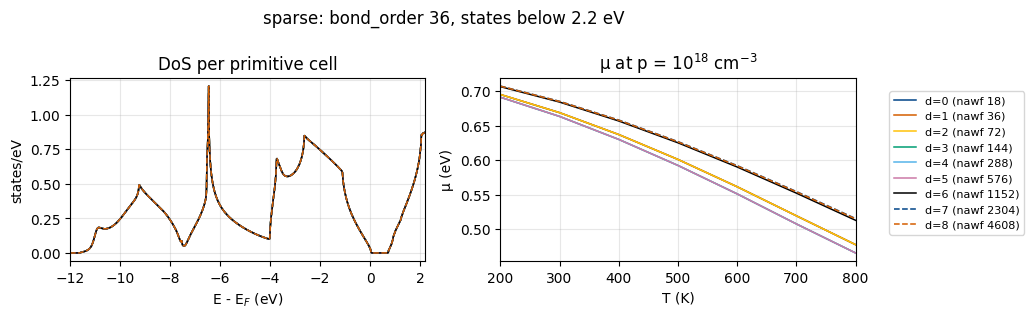

In [3]:
show(['dos', 'doping_mu'], ncol=2)

## 2. Boltzmann transport

Constant relaxation time, at 300 K, against the chemical potential. The Hall tensor trace needs
the full spectrum at every k-point, so only `sparse_curvature` has it.

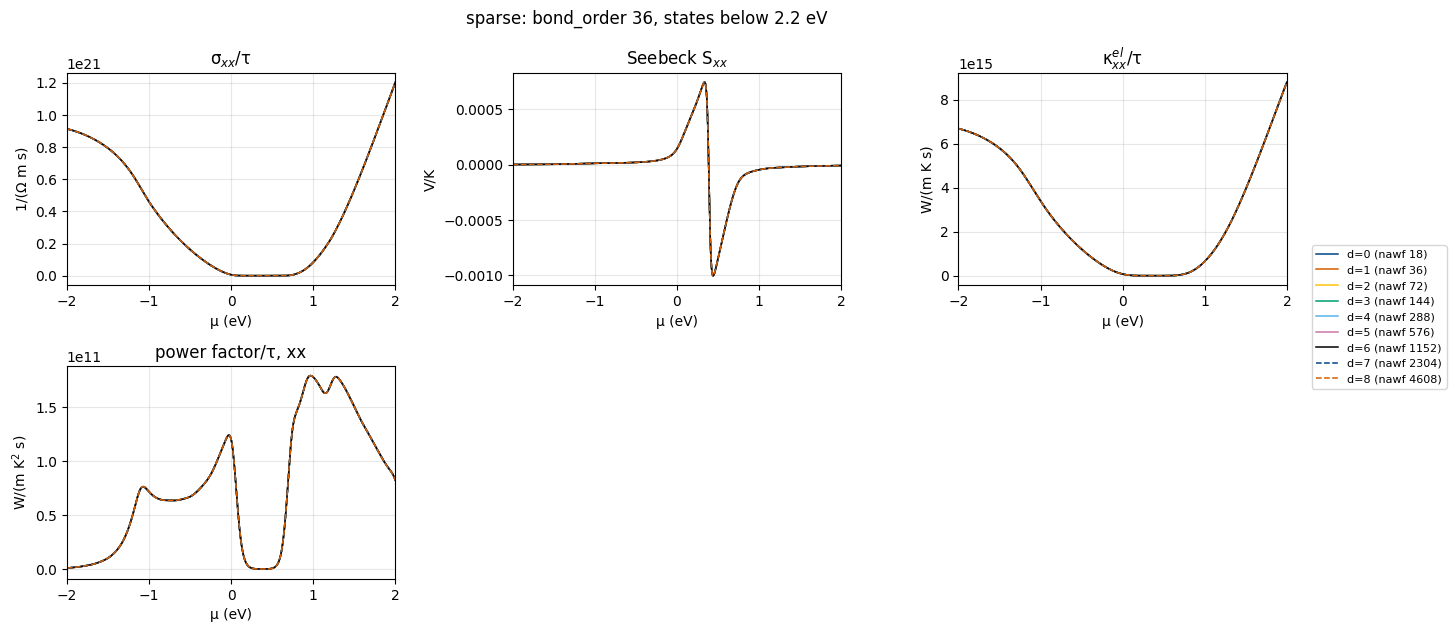

In [4]:
show(['sigma_xx', 'seebeck_xx', 'kappa_xx', 'pf_xx', 'hall_trace'])

## 3. Band-diagonal conductivity

σ_xy vanishes by cubic symmetry, so its curve should stay at zero next to σ_xx.

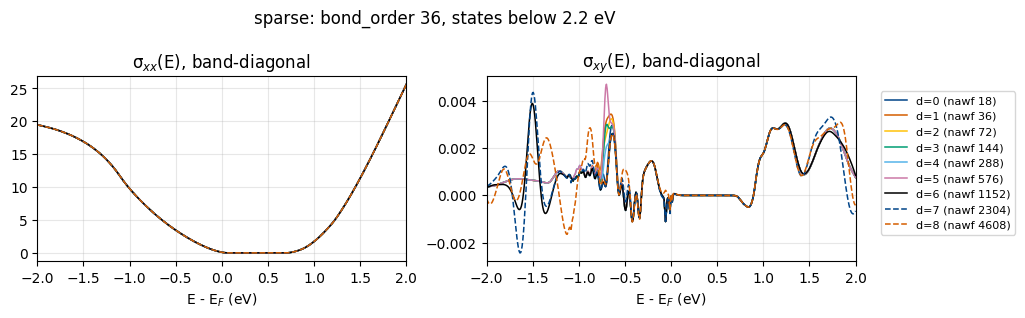

In [5]:
show(['cond_xx', 'cond_xy'], ncol=2)

## 4. Optical response

Kubo-Greenwood dielectric function and the optical constants built from it. The grey line is the
energy-window top minus 0.5 eV: above it, ε″ of a window run misses the transitions into states
above the window. ε′ and everything derived from it (EELS, R, n, κ, α, σ(ω)) need transitions at
all energies, so for a window run they differ from the reference at every ω.

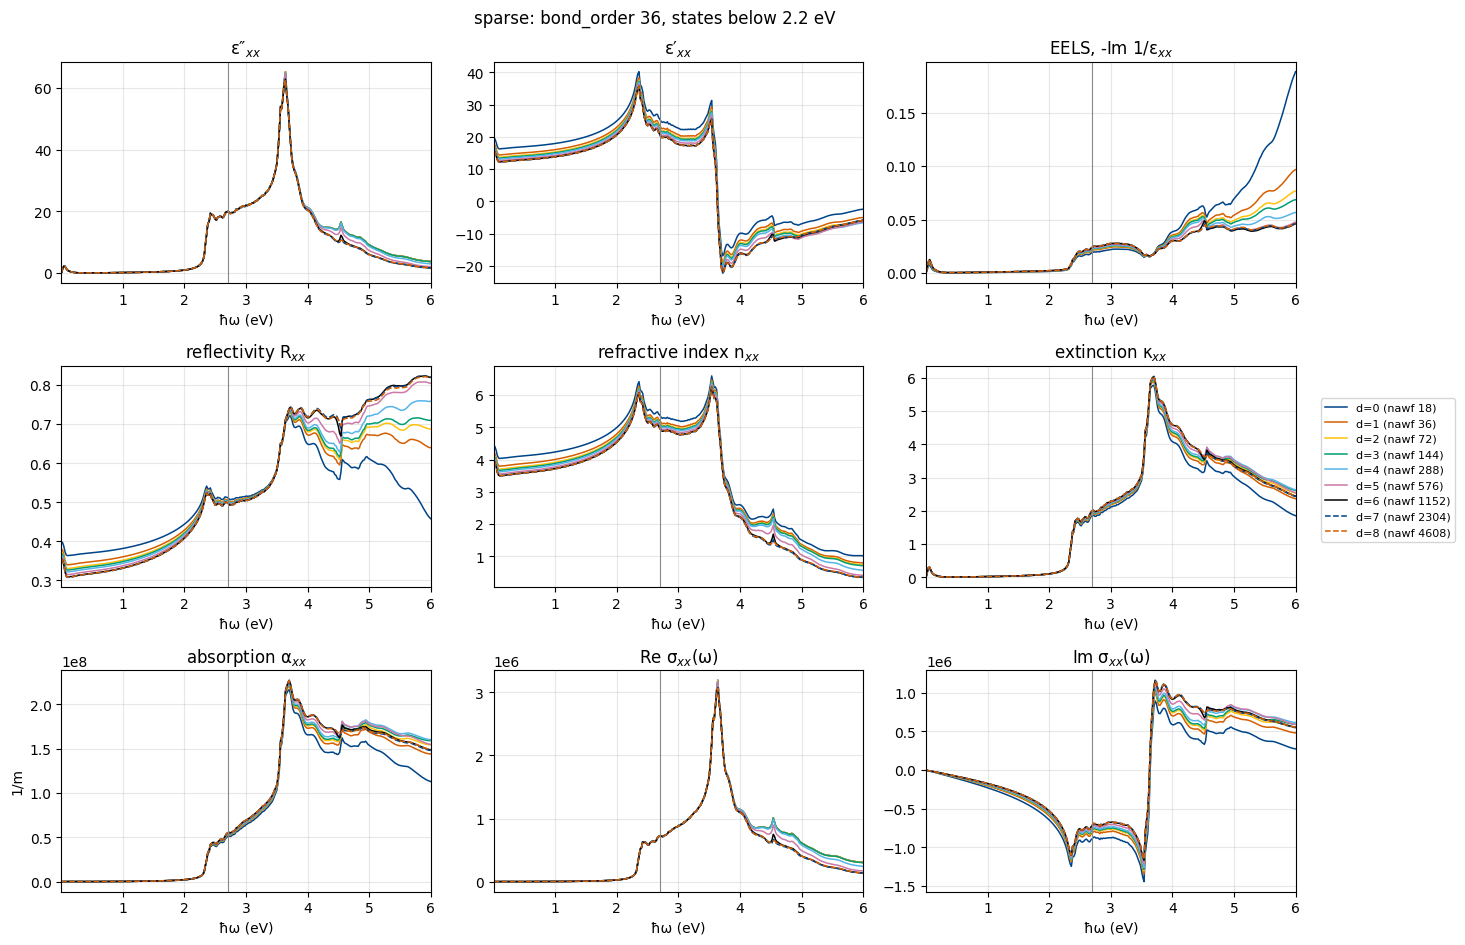

In [6]:
show(
    [
        'epsi_xx',
        'epsr_xx',
        'eels_xx',
        'refl_xx',
        'nref_xx',
        'kref_xx',
        'alpha_xx',
        'sigmar_xx',
        'sigmai_xx',
    ]
)

## 5. Effective masses

The per-state masses of `effective_masses_0.dat` cannot be compared line by line across sizes,
so they are shown as a smeared density of inverse DoS masses, Σ g(E − E_nk) / m_dos,nk, per
k-point of the primitive cell.

In [8]:
show(['inv_mass_dos'], ncol=1)